# Experiment No. 09: K-Means Clustering Algorithm

## Aim

To implement the K-Means Clustering algorithm to partition a given dataset into multiple clusters based on the similarity of its features, and to analyze the resulting groups using appropriate clustering evaluation methods.

## Objectives

1. To understand the basic concept and working principle of K-Means Clustering.
2. To implement K-Means Clustering on a dataset using Python and Scikit-learn.
3. To group data points into K distinct clusters based on feature similarity.
4. To determine suitable cluster centroids and assign data points to their nearest centroids.
5. To use the Elbow Method to investigate a suitable number of clusters.
6. To visualize the formed clusters and interpret the clustering results.
7. To evaluate clustering quality using the Silhouette Score.

## Relevance

K-Means Clustering is a widely used unsupervised machine learning algorithm for discovering natural groups and patterns in unlabeled data. It is relevant to applications such as customer segmentation, image segmentation, document grouping, market analysis, and pattern recognition.

By grouping similar data points into clusters, K-Means helps reveal the structure and characteristics of complex datasets without requiring predefined class labels.

## Theory

### 1. Introduction to K-Means Clustering

K-Means is an unsupervised machine learning algorithm that partitions a dataset into K clusters. Each cluster is represented by a centroid, which is the mean position of the data points assigned to that cluster.

The algorithm attempts to place similar observations in the same cluster while separating observations that are relatively different.

### 2. Working Principle

The algorithm follows these steps:

1. Select the number of clusters, K.
2. Initialize K centroids using a method such as K-Means++.
3. Calculate the distance between each data point and the centroids.
4. Assign each point to its nearest centroid.
5. Recalculate each centroid as the mean of the points assigned to its cluster.
6. Repeat the assignment and update steps until convergence or the maximum number of iterations is reached.

### 3. Euclidean Distance

K-Means commonly uses Euclidean distance to measure the distance between observations.

For two points P(x₁, y₁) and Q(x₂, y₂):

d(P, Q) = √[(x₂ − x₁)² + (y₂ − y₁)²]

A smaller distance indicates that the points are closer in the selected feature space.

### 4. Objective Function

K-Means minimizes the Within-Cluster Sum of Squares (WCSS), also called inertia.

WCSS = Σ(i=1 to K) Σ(x ∈ Cᵢ) ||x − μᵢ||²

Where:

- K = Number of clusters
- Cᵢ = Set of data points in cluster i
- x = Data point
- μᵢ = Centroid of cluster i

A lower WCSS indicates that observations are closer to their assigned centroids. However, WCSS generally decreases as K increases, so it should not be used alone to select K.

### 5. Selection of K: Elbow Method

The Elbow Method calculates WCSS for several values of K and plots the results. A possible suitable value is the point where the decrease in WCSS begins to slow noticeably.

### 6. Feature Scaling

K-Means is distance-based. Features with larger numerical ranges can dominate the distance calculation. StandardScaler standardizes features by subtracting the mean and dividing by the standard deviation.

z = (x − μ) / σ

Where x is the original value, μ is the feature mean, and σ is the feature standard deviation.

### 7. Clustering Evaluation

The Silhouette Score measures how well observations fit their assigned clusters compared with other clusters. Its value ranges from -1 to +1.

- Near +1: Observations are generally well separated from other clusters.
- Near 0: Clusters may overlap.
- Below 0: Some observations may be assigned to less suitable clusters.

### 8. Dataset Used

This experiment uses the Iris dataset available in Scikit-learn. It contains 150 observations and four numerical measurements of iris flowers.

For visualization, this notebook uses two features:

- Petal length (cm)
- Petal width (cm)

The species labels are not used to train K-Means. They are used only after clustering for optional external evaluation and interpretation.

### 9. Limitations

- The number of clusters must be selected in advance.
- Results can depend on centroid initialization.
- Feature scaling can affect the resulting clusters.
- K-Means may not perform well on clusters with irregular shapes or substantially different densities.
- Clustering assignments do not automatically correspond to actual species or categories.

## Software and Libraries

- Python
- Jupyter Notebook
- NumPy
- Pandas
- Matplotlib
- Scikit-learn

## Step 1: Import Required Libraries

### Purpose
Import the Python libraries required for data manipulation, visualization, clustering, preprocessing, and evaluation.

### Explanation
- NumPy supports numerical operations.
- Pandas organizes data into DataFrames.
- Matplotlib creates graphs.
- `load_iris()` loads the Iris dataset.
- `StandardScaler` standardizes the selected features.
- `KMeans` implements the clustering algorithm.
- `silhouette_score` evaluates cluster separation.
- `adjusted_rand_score` compares cluster assignments with known labels for optional post-clustering analysis.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("All required libraries imported successfully.")

All required libraries imported successfully.


## Step 2: Load the Iris Dataset

### Purpose
Load the Iris dataset and prepare its numerical features and species labels.

### Explanation
The Iris dataset contains 150 observations, four numerical features, and three species categories.

The species labels are retained for later interpretation only. They will not be provided to the K-Means model during training.

In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

print("Dataset loaded successfully.")
print("Number of observations:", df.shape[0])
print("Number of features:", len(iris.feature_names))

Dataset loaded successfully.
Number of observations: 150
Number of features: 4


## Step 3: Display the First Five Records

### Purpose
Inspect the first five observations to understand the dataset's structure.

### Explanation
The `head()` method displays the first five rows by default. The output includes four numerical measurements and the species label, which is reserved for later interpretation.

In [3]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 4: Examine Dataset Dimensions and Information

### Purpose
Check the number of rows, columns, and data types.

### Explanation
The `shape` attribute provides the dataset dimensions. The `info()` method displays column names, non-null counts, and data types, helping identify potential preprocessing requirements.

In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB


## Step 5: Generate Descriptive Statistics

### Purpose
Understand the distribution and numerical range of the dataset features.

### Explanation
The `describe()` method calculates the count, mean, standard deviation, minimum, quartiles, and maximum for each numerical feature.

These statistics help identify differences in feature ranges before applying distance-based clustering.

In [5]:
df[iris.feature_names].describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## Step 6: Check Missing Values and Duplicate Records

### Purpose
Check the dataset for missing values and duplicate observations.

### Explanation
Missing values can interfere with model fitting, while duplicate observations may influence cluster centroids. The checks below report both conditions without automatically deleting any records.

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Number of duplicate rows: 1


## Step 7: Select Features for Clustering

### Purpose
Choose the numerical features that will be used by K-Means.

### Explanation
This experiment uses petal length and petal width because two-dimensional data can be visualized clearly using a scatter plot.

The species column is excluded. Therefore, the clustering algorithm discovers groups based only on numerical feature similarity.

In [7]:
feature_names = [
    "petal length (cm)",
    "petal width (cm)"
]

X = df[feature_names].copy()

print("Selected features:")
print(X.head())

print("\nFeature matrix shape:", X.shape)

Selected features:
   petal length (cm)  petal width (cm)
0                1.4               0.2
1                1.4               0.2
2                1.3               0.2
3                1.5               0.2
4                1.4               0.2

Feature matrix shape: (150, 2)


## Step 8: Visualize the Original Feature Distribution

### Purpose
Explore the relationship between petal length and petal width before clustering.

### Explanation
The scatter plot displays the selected numerical features without applying K-Means. It helps reveal the general structure of the data.

Each point represents one flower observation. At this stage, the plot is not colored by species or predicted cluster.

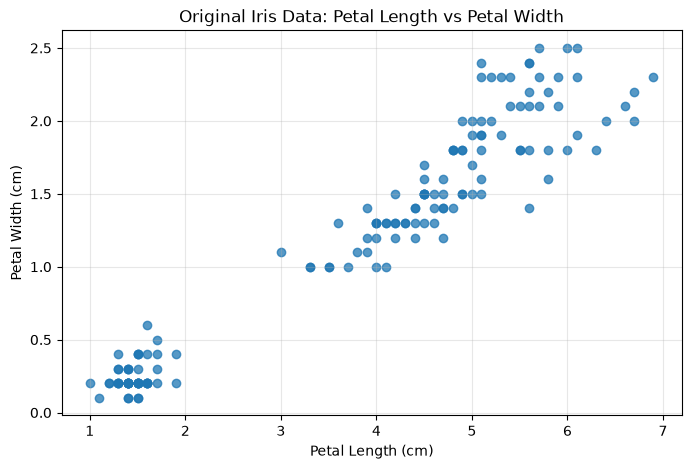

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[feature_names[0]],
    X[feature_names[1]],
    alpha=0.75
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Original Iris Data: Petal Length vs Petal Width")
plt.grid(alpha=0.3)
plt.show()

## Step 9: Standardize the Selected Features

### Purpose
Scale both selected features to comparable numerical ranges.

### Explanation
K-Means uses distance calculations. If features have different scales, a feature with a larger range may have a disproportionate effect on cluster assignments.

`StandardScaler` transforms each feature to have approximately zero mean and unit standard deviation. It is fitted on the selected dataset for this exploratory clustering experiment.

In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed.")
print("Scaled data shape:", X_scaled.shape)

Standardization completed.
Scaled data shape: (150, 2)


## Step 10: Inspect the Standardized Features

### Purpose
Display the transformed feature values and verify the effect of standardization.

### Explanation
The standardized feature values are stored in a NumPy array. Converting them into a DataFrame makes the values easier to inspect.

The transformed values are used for the subsequent K-Means fitting, Elbow Method, and Silhouette Score calculations.

In [10]:
scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_names
)

print("First five standardized observations:")
display(scaled_df.head())

print("\nStandardized feature means:")
print(scaled_df.mean().round(4))

print("\nStandardized feature standard deviations:")
print(scaled_df.std(ddof=0).round(4))

First five standardized observations:


,petal length (cm),petal width (cm)
0,-1.340227,-1.315444
1,-1.340227,-1.315444
2,-1.397064,-1.315444
3,-1.283389,-1.315444
4,-1.340227,-1.315444



Standardized feature means:
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64

Standardized feature standard deviations:
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


## Step 11: Calculate WCSS for Different Values of K

### Purpose
Calculate the Within-Cluster Sum of Squares (WCSS), also known as inertia, for values of K from 1 to 10.

### Explanation
For each value of K, a K-Means model is fitted to the standardized features. The `inertia_` attribute records the sum of squared distances from observations to their assigned centroids.

These values are used to construct the Elbow Method graph.

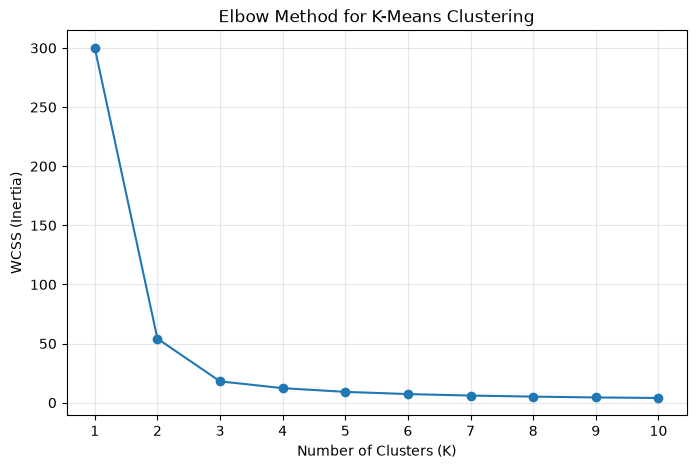

In [12]:
# Elbow Method: Calculate and Plot WCSS

k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

## Step 12: Plot the Elbow Method Graph

### Purpose
Visualize how WCSS changes as the number of clusters increases.

### Explanation
WCSS generally decreases when additional clusters are introduced. The Elbow Method looks for a point where the improvement begins to diminish.

The graph helps identify candidate values of K. The elbow is an estimate rather than a guaranteed optimal solution.

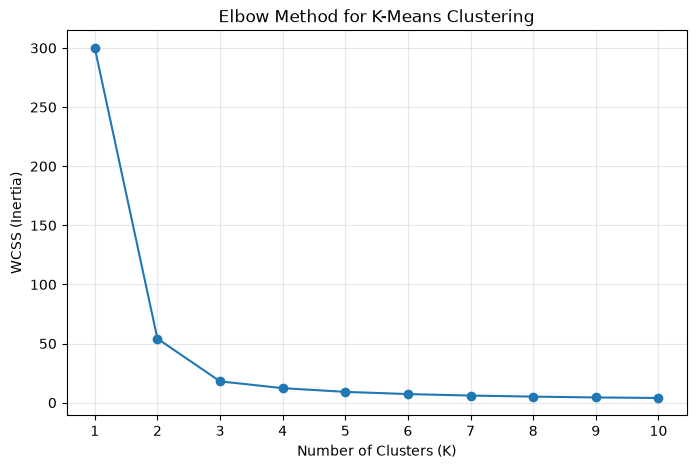

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

## Step 13: Calculate Silhouette Scores for Candidate K Values

### Purpose
Evaluate clustering quality for K values from 2 to 6.

### Explanation
The Silhouette Score compares how close an observation is to its own cluster with how close it is to other clusters.

The score ranges from -1 to +1. Higher values generally indicate better separation and cohesion.

K = 1 is excluded because a Silhouette Score requires at least two clusters.

In [14]:
silhouette_results = []

candidate_k_values = range(2, 7)

for k in candidate_k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    cluster_labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

silhouette_df

,K,Silhouette Score
0,2,0.743372
1,3,0.674131
2,4,0.598802
3,5,0.573563
4,6,0.581791


## Step 14: Visualize Silhouette Scores

### Purpose
Compare the Silhouette Scores for the candidate cluster counts.

### Explanation
The bar chart helps identify which tested value of K produces the highest Silhouette Score.

The score should be considered together with the Elbow Method and the interpretability of the resulting clusters. The highest score alone does not guarantee that the chosen clusters are the most useful for every application.

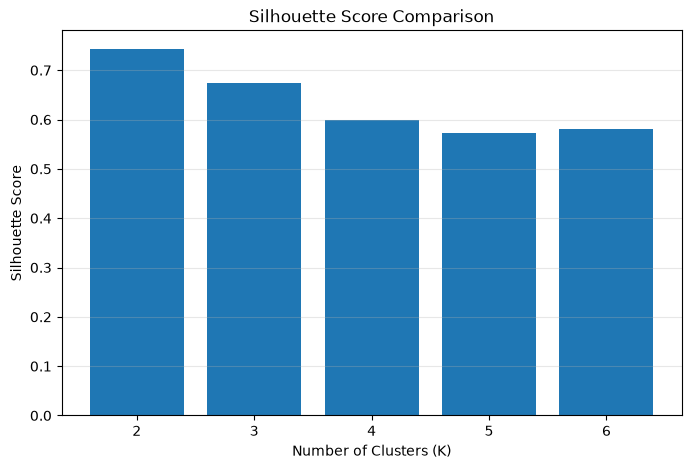

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"]
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.xticks(list(candidate_k_values))
plt.grid(axis="y", alpha=0.3)
plt.show()

## Step 15: Train the Final K-Means Model

### Purpose
Fit the final K-Means model using three clusters.

### Explanation
For this experiment, K = 3 is selected to demonstrate grouping on the Iris dataset and to allow later comparison with its three known species categories.

This choice is an experimental setting, not a claim that the Elbow Method or Silhouette Score must always select three clusters.

Important parameters:

- `n_clusters=3`: Creates three clusters.
- `init="k-means++"`: Uses a centroid initialization strategy that helps choose well-spaced initial centroids.
- `n_init=10`: Runs the initialization procedure ten times and retains the solution with the lowest inertia.
- `random_state=42`: Supports reproducible results.

In [17]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans.fit(X_scaled)

print("K-Means model trained successfully.")
print("Number of clusters:", kmeans.n_clusters)
print("Number of iterations:", kmeans.n_iter_)
print("Final WCSS:", round(kmeans.inertia_, 4))

K-Means model trained successfully.
Number of clusters: 3
Number of iterations: 6
Final WCSS: 18.027


## Step 16: Assign Cluster Labels to Observations

### Purpose
Assign each observation to one of the three clusters produced by the trained model.

### Explanation
The `predict()` method assigns each observation to its nearest fitted centroid in standardized feature space.

The cluster labels are numbered 0, 1, and 2. These numbers are arbitrary identifiers and do not represent a ranking or actual species names.

In [18]:
cluster_labels = kmeans.predict(X_scaled)

clustered_df = X.copy()
clustered_df["Cluster"] = cluster_labels

print("First ten cluster assignments:")
display(clustered_df.head(10))

print("\nUnique cluster labels:")
print(np.unique(cluster_labels))

First ten cluster assignments:


,petal length (cm),petal width (cm),Cluster
0,1.4,0.2,1
1,1.4,0.2,1
2,1.3,0.2,1
3,1.5,0.2,1
4,1.4,0.2,1
5,1.7,0.4,1
6,1.4,0.3,1
7,1.5,0.2,1
8,1.4,0.2,1
9,1.5,0.1,1



Unique cluster labels:
[0 1 2]


## Step 17: Count Observations in Each Cluster

### Purpose
Determine how many observations have been assigned to each cluster.

### Explanation
The `value_counts()` method counts observations belonging to each predicted cluster. Sorting by cluster label makes the results easier to interpret.

Different cluster sizes are possible because K-Means does not require every cluster to contain the same number of observations.

In [19]:
cluster_counts = (
    clustered_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Number of observations in each cluster:")
display(cluster_counts.to_frame(name="Number of Observations"))

print("\nTotal assigned observations:", cluster_counts.sum())

Number of observations in each cluster:


,Number of Observations
Cluster,
0,48
1,50
2,52



Total assigned observations: 150


## Step 18: Visualize the Formed Clusters and Centroids

### Purpose
Plot the observations using their predicted cluster labels and display the cluster centroids.

### Explanation
Each color represents a cluster discovered by K-Means. The centroid markers indicate the mean positions of the clusters in standardized feature space.

The plot uses the same standardized features that were supplied to the model. Therefore, the centroid coordinates can be plotted directly with the scaled observations.

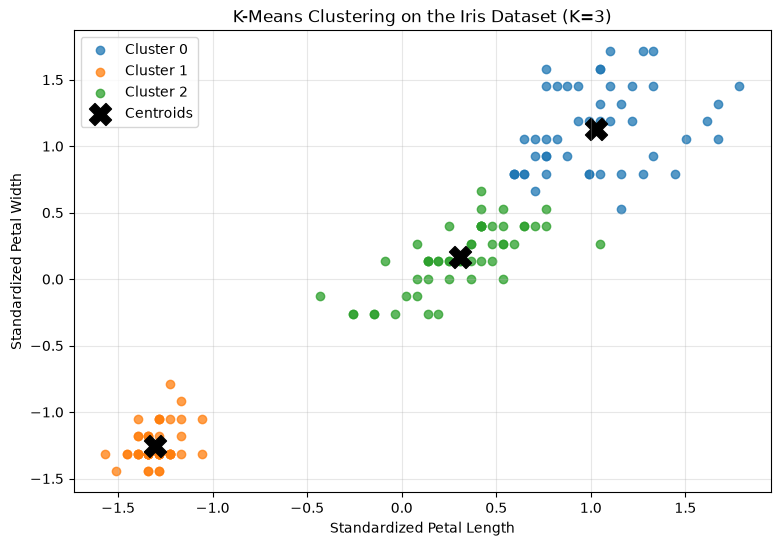

In [20]:
plt.figure(figsize=(9, 6))

for cluster_id in range(kmeans.n_clusters):
    mask = cluster_labels == cluster_id

    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.75
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.xlabel("Standardized Petal Length")
plt.ylabel("Standardized Petal Width")
plt.title("K-Means Clustering on the Iris Dataset (K=3)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 19: Interpret the Cluster Centroids

### Purpose
Convert the fitted centroid coordinates back into the original feature scale.

### Explanation
The K-Means model was trained on standardized features. Applying `inverse_transform()` converts the centroid coordinates back to petal length and petal width in centimetres.

These values describe the mean feature position of each cluster and help interpret the groups in terms of the original measurements.

In [21]:
centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=feature_names
)

centroid_df.index.name = "Cluster"

print("Cluster centroids in original units:")
display(centroid_df.round(3))

Cluster centroids in original units:


,petal length (cm),petal width (cm)
Cluster,,
0,5.567,2.056
1,1.462,0.246
2,4.296,1.325


## Step 20: Evaluate and Summarize the Clustering Results

### Purpose
Calculate the final Silhouette Score and compare the cluster assignments with the known Iris species labels for supplementary analysis.

### Explanation
The Silhouette Score evaluates the internal quality of the clustering using the standardized features.

The Adjusted Rand Index (ARI) compares the predicted clusters with the known species categories. It is included only as an external evaluation measure after clustering. The species labels are not used to train the K-Means model.

ARI is adjusted for chance and ranges from -1 to 1; a value closer to 1 indicates stronger agreement between the cluster assignments and the known categories.

The comparison is informative, but K-Means is not required to reproduce the species labels exactly.

In [22]:
final_silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

ari_score = adjusted_rand_score(
    iris.target,
    cluster_labels
)

clustered_df["Actual Species"] = df["species"].astype(str).values

print("Final Clustering Evaluation")
print("-" * 35)
print("Number of clusters:", kmeans.n_clusters)
print("Number of observations:", len(cluster_labels))
print("Final WCSS:", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(final_silhouette, 4))
print("Adjusted Rand Index:", round(ari_score, 4))

print("\nCluster vs. Actual Species (post-clustering comparison):")

display(
    pd.crosstab(
        clustered_df["Cluster"],
        clustered_df["Actual Species"]
    )
)

print("\nMean original feature values by cluster:")

display(
    clustered_df.groupby("Cluster")[feature_names]
    .mean()
    .round(3)
)

Final Clustering Evaluation
-----------------------------------
Number of clusters: 3
Number of observations: 150
Final WCSS: 18.027
Silhouette Score: 0.6741
Adjusted Rand Index: 0.8857

Cluster vs. Actual Species (post-clustering comparison):


Actual Species,setosa,versicolor,virginica
Cluster,,,
0,0,2,46
1,50,0,0
2,0,48,4



Mean original feature values by cluster:


,petal length (cm),petal width (cm)
Cluster,,
0,5.567,2.056
1,1.462,0.246
2,4.296,1.325


# Conclusion

The K-Means Clustering algorithm was successfully implemented using Python and Scikit-learn on the Iris dataset.

The experiment covered data exploration, feature selection, standardization, cluster-count investigation using the Elbow Method, evaluation using the Silhouette Score, model training, cluster assignment, centroid visualization, and interpretation of the results.

The final model grouped the observations into three clusters based on petal length and petal width. The centroids helped describe the average feature values of the resulting groups.

The Silhouette Score was used to assess internal clustering quality, while the Adjusted Rand Index and cluster-versus-species table provided supplementary comparisons with the known species labels. These labels were not used to train the clustering model.

This experiment demonstrates that K-Means is a useful unsupervised learning technique for discovering groups in numerical data. It also highlights the importance of feature scaling, appropriate cluster selection, visualization, and careful interpretation of evaluation metrics.